In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return x**2+5*x+2

In [3]:
f(3)

26

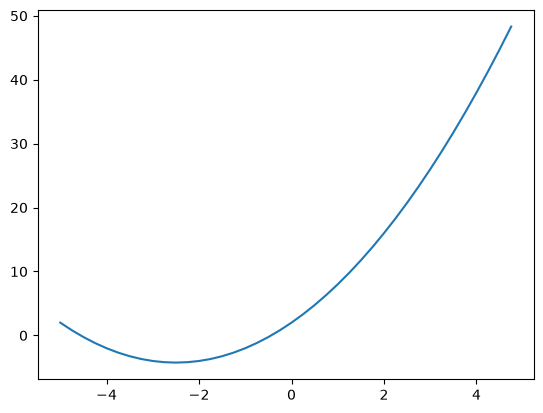

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [5]:
h = 0.00000000001
x=-2.5
(f(x+h)-f(x))/h

8.881784197001252e-05

In [6]:
a = 2
b = -3
c = 10
d = a*b+c
print(d)

4


In [7]:
h = 0.0001
a = 2
b = -3
c = 10
d1 = a*b+c
c+=h
d2 =  a*b+c
print("d1", d1)
print("d2", d2)
print("slope ",(d2-d1)/h )

d1 4
d2 4.0001
slope  0.9999999999976694


In [97]:
class Value:
    def __init__(self, data, children=(), _op='', label = ''):
        self.data = data
        self._prev = set(children)
        self._backward = lambda:None
        self._op = _op
        self.label = label
        self.grad = 0
    def __repr__(self):
        return f"Value(data={self.data})"
    def __neg__(self):
        return self*(-1)
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data+other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out
    def __sub__(self, other):
        return self+(-other)
    def __rmul__(self, other):
        return self*other
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data*other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    def __pow__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data**other.data, (self, other), '**')
        def _backward():
            self.grad += other.data*(self.data**(other.data-1))*out.grad
            other.grad += math.log(self.data)*math.exp(other.data*math.log(self.data))*out.grad
        out._backward = _backward
        return out
    def __truediv__(self, other):
        return self*(other**-1)
    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t, (self,), 'tanh')
        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward
        return out
    def exp(self):
        out = Value(math.exp(self.data), (self,), 'exp')
        def _backward():
            self.grad+= out.data * out.grad
        out._backward = _backward
        return out
    def backward(self):
        topo = []
        visited = set()
        def topological_order(v):
            if v not in visited:
                visited.add(v)
                for c in v._prev:
                    topological_order(c)
                topo.append(v)
        topological_order(self)

        self.grad = 1.0
        for c in reversed(topo):
            c._backward()



    # def backprop(self, parent= None):
    #     if parent!= None: 
    #         self.grad *= parent.grad
    #         if parent._op=='+':
    #             self.grad*=1
    #         elif parent._op=='*':
    #             for child in parent._prev:
    #                 self.grad*= child.data
    #             self.grad/= self.data
    #         elif parent._op == 'tanh':
    #             self.grad = 1 - parent.data**2
    #     for child in self._prev:
    #         child.backprop(self)

        



a = Value(2.0, label='a')
b = Value(-3, label = 'b')
c = Value(10, label='c')
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'
d


Value(data=4.0)

In [23]:
from graphviz import Digraph
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad ), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)
  
  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  
  return dot

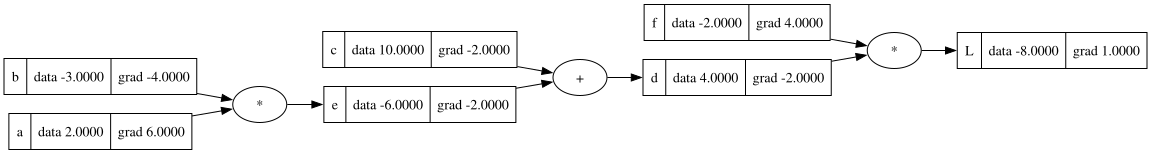

In [25]:
draw_dot(L)

In [28]:
def test():
    h=0.0001
    a = Value(2.0, label='a')
    b = Value(-3, label = 'b')
    c = Value(10, label='c')
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L1 = d*f; L.label = 'L'

    a = Value(2.0, label='a')
    b = Value(-3+h, label = 'b')
    c = Value(10, label='c')
    e = a*b; e.label = 'e'
    d = e+c; d.label = 'd'
    f = Value(-2.0, label='f')
    L2 = d*f; L.label = 'L'

    print((L2.data-L1.data)/h)
test()

-4.000000000008441


In [93]:
# Input x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.01, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label = 'w2')
# Bias b
b = Value(6.7, label = 'b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label = 'x1w1+x2w2'
n = x1w1x2w2+b; n.label = 'n'
o = n.tanh(); o.label = 'o'

o.backward()



In [99]:
# Input x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.01, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label = 'w2')
# Bias b
b = Value(6.7, label = 'b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1+x2w2; x1w1x2w2.label = 'x1w1+x2w2'
n = x1w1x2w2+b; n.label = 'n'
e = (2*n).exp(); e.label = 'e'
o = (e-1)/(e+1); o.label = 'o'

o.backward()



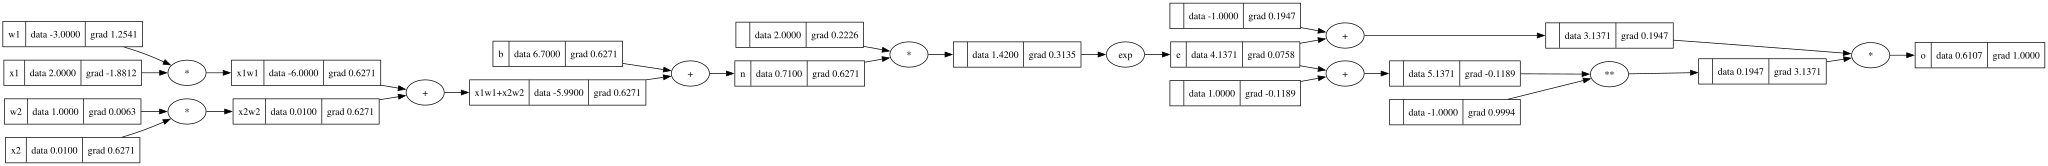

In [100]:
draw_dot(o)

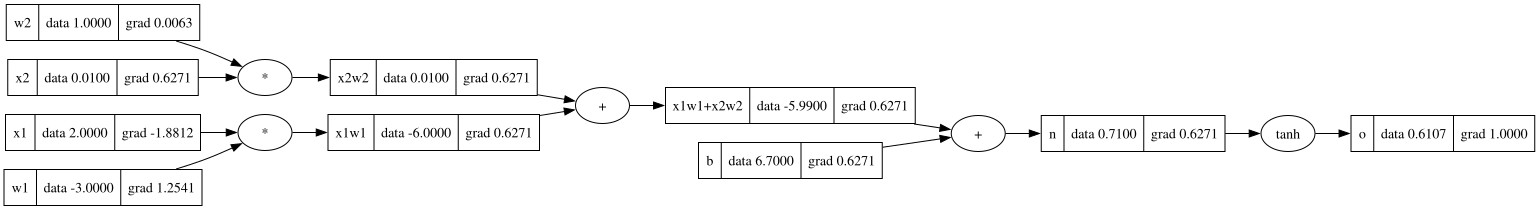

In [94]:
draw_dot(o)

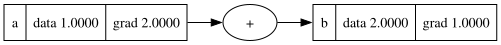

In [74]:
a = Value(1, label='a')
b = a+a; b.label = 'b'
b.backward()
draw_dot(b)

In [ ]:
import torch
